# From T1 and T2 to a noise model

## The problem

The benchmarking notebook ended with two numbers for a qubit, $T_1$ and $T_2$. Numbers on a calibration page do not run circuits. What we want is a **noise model**: a rule that tells a simulator what the device does to a state while it waits, so we can predict the output of a circuit *before* spending hardware time on it.

The rule has to be built from only $T_1$ and $T_2$, and it must agree with the decay curves we already fitted. This notebook builds it in four steps and checks it against those curves.

The tool is the **Kraus operator**. A qubit that is alone evolves by a unitary matrix (one that preserves length). A qubit that is slowly leaking into its surroundings cannot be described by one matrix, but it can be described by a short list of them, and the list is the noise.

## The workflow

| Step | What it does | Code |
|---|---|---|
| 1. Operator | Build Kraus operators from $T_1$ and $T_2$ | `ops.py` |
| 2. Encoding | Build simple circuits: prepare a state, then idle | `encoding.py` |
| 3. Execution | Attach the operators to the idle gate and simulate | `execution.py` |
| 4. Analysis | Compare the noise model with the benchmarking formulas | `analysis.py` |

The same steps run from the command line with `python noise_model/main.py`, started in `../scripts/`. Times are in microseconds.

## Setup

`T1` and `T2` are the values built into the benchmarking simulator. To model a real qubit, replace them with the times you measured on `ibm_rensselaer`. `STEP` is the duration of one idle step.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

# The noise-model code lives in ../scripts/noise_model.
# Run this notebook from its own folder (the Jupyter default).
sys.path.insert(0, str(Path("../scripts/noise_model").resolve()))

import analysis
import encoding as enc
import execution
import ops

%matplotlib inline

T1 = 100.0  # microseconds
T2 = 70.0  # microseconds
STEP = 1.0  # microseconds per idle step

## Step 1: The operator (Kraus operators)

### The density matrix

A state vector $|\psi\rangle$ describes a qubit that is perfectly known. Once noise acts, our knowledge is statistical (the qubit *might* have fallen to $|0\rangle$), so we describe the qubit with a **density matrix**, a $2\times2$ complex matrix

$$\rho = \begin{pmatrix} p_0 & c \\ c^* & p_1 \end{pmatrix}.$$

The diagonal entries, called the **populations**, are the probabilities of reading 0 and 1. The off-diagonal $c$ is the **coherence**: the phase information that interference uses. For a known state, $\rho = |\psi\rangle\langle\psi|$.

- $|1\rangle$ gives $\rho = \begin{pmatrix}0&0\\0&1\end{pmatrix}$. All the weight is on the bit, and there is no coherence.
- $|+\rangle$ gives $\rho = \tfrac12\begin{pmatrix}1&1\\1&1\end{pmatrix}$. The off-diagonal $c = \tfrac12$ is as large as it can be.

$T_1$ drains the bottom-right entry. $T_2$ shrinks the off-diagonal entry. That is all the noise does.

In [2]:
one = np.array([[0, 0], [0, 1]], dtype=complex)  # |1><1|
plus = np.array([[1, 1], [1, 1]], dtype=complex) / 2  # |+><+|
print("rho for |1>:\n", one.real)
print("rho for |+>:\n", plus.real)

rho for |1>:
 [[0. 0.]
 [0. 1.]]
rho for |+>:
 [[0.5 0.5]
 [0.5 0.5]]


### What a Kraus operator does

Noise acts on $\rho$ through a list of matrices $K_0, K_1, \dots$:

$$\rho \;\longrightarrow\; \sum_i K_i\,\rho\,K_i^\dagger, \qquad \text{with}\quad \sum_i K_i^\dagger K_i = I.$$

Here $K^\dagger$ is the conjugate transpose of $K$ and $I$ is the identity matrix.

Read it as: *with some probability the environment did $K_0$ to the qubit, with some probability it did $K_1$, and we do not know which, so we add up the outcomes.* The condition on the right keeps the total probability at 1. With a single operator the sum is $K\rho K^\dagger$, an ordinary unitary gate. Several operators are what make the evolution irreversible.

### Amplitude damping: T1

During a wait of duration $t$, a qubit in $|1\rangle$ falls to $|0\rangle$ with probability $\gamma = 1 - e^{-t/T_1}$. The two cases are

$$K_0 = \begin{pmatrix}1&0\\0&\sqrt{1-\gamma}\end{pmatrix}, \qquad K_1 = \begin{pmatrix}0&\sqrt{\gamma}\\0&0\end{pmatrix}.$$

$K_0$ is the case where nothing fell. $K_1$ is the case where $|1\rangle$ became $|0\rangle$.

$K_1$ turns $|1\rangle$ into $|0\rangle$ and kills $|0\rangle$, which is exactly a fall. $K_0$ is the "no fall yet" branch, and it slightly shrinks the amplitude of $|1\rangle$, because *not* having fallen is evidence that the qubit is still up.

In [3]:
t = 50.0  # one wait of 50 us
amp = ops.amplitude_damping(t, T1)
print("gamma =", round(1 - np.exp(-t / T1), 4))
print("K0 =\n", amp[0].round(4))
print("K1 =\n", amp[1].round(4))
print("completeness error:", ops.check_complete(amp))

after = ops.apply_channel(amp, one)
print("\nrho after the wait, starting from |1>:\n", after.real.round(4))
print("p1 =", round(after[1, 1].real, 4), "  formula exp(-t/T1) =", round(np.exp(-t / T1), 4))

gamma = 0.3935
K0 =
 [[1.     0.    ]
 [0.     0.7788]]
K1 =
 [[0.     0.6273]
 [0.     0.    ]]
completeness error: 0.0

rho after the wait, starting from |1>:
 [[0.3935 0.    ]
 [0.     0.6065]]
p1 = 0.6065   formula exp(-t/T1) = 0.6065


The bottom-right entry of $\rho$ is the probability of still being in $|1\rangle$, and it equals $e^{-t/T_1}$. The Kraus operators reproduce the T1 decay from the benchmarking notebook, and $T_1$ is the only number they used.

### Phase damping: the rest of T2

Amplitude damping also costs coherence. A qubit that might have fallen has a less certain phase, and the off-diagonal entry shrinks by $\sqrt{1-\gamma} = e^{-t/2T_1}$. So $T_1$ alone gives a coherence time of $2T_1$. A real qubit does worse, $T_2 \le 2T_1$, and the extra loss is **pure dephasing** with its own time $T_\varphi$. The rates add:

$$\frac{1}{T_2} = \frac{1}{2T_1} + \frac{1}{T_\varphi}.$$

For pure dephasing, the environment learns whether the qubit is in $|1\rangle$ and scrambles its phase with probability $\lambda$:

$$K_0 = \begin{pmatrix}1&0\\0&\sqrt{1-\lambda}\end{pmatrix}, \qquad K_1 = \begin{pmatrix}0&0\\0&\sqrt{\lambda}\end{pmatrix}.$$

The populations on the diagonal do not change, because $K_0^\dagger K_0 + K_1^\dagger K_1 = I$ and neither operator moves weight between $|0\rangle$ and $|1\rangle$. Only the off-diagonal is multiplied by $\sqrt{1-\lambda}$. We want that factor to be $e^{-t/T_\varphi}$, so $\lambda = 1 - e^{-2t/T_\varphi}$.

In [4]:
Tphi = ops.dephasing_time(T1, T2)
print(f"T_phi = {Tphi:.1f} us   (from 1/T2 = 1/(2 T1) + 1/T_phi)")

phase = ops.phase_damping(t, T1, T2)
print("completeness error:", ops.check_complete(phase))

after = ops.apply_channel(phase, plus)
print("\nrho after the wait, starting from |+>:\n", after.real.round(4))
print("coherence c =", round(after[0, 1].real, 4), "  formula 0.5 exp(-t/T_phi) =", round(0.5 * np.exp(-t / Tphi), 4))

T_phi = 107.7 us   (from 1/T2 = 1/(2 T1) + 1/T_phi)
completeness error: 0.0

rho after the wait, starting from |+>:
 [[0.5    0.3143]
 [0.3143 0.5   ]]
coherence c = 0.3143   formula 0.5 exp(-t/T_phi) = 0.3143


### Both together

Time passes and both processes act. We apply one channel and then the other. Doing so multiplies every operator of the second list by every operator of the first, so we get $2\times2 = 4$ Kraus operators. The coherence is now multiplied by $e^{-t/2T_1}\cdot e^{-t/T_\varphi} = e^{-t/T_2}$, as it should be.

In [5]:
kraus = ops.relaxation_kraus(STEP, T1, T2)
print(f"One idle step of {STEP} us has {len(kraus)} Kraus operators:")
for i, k in enumerate(kraus):
    print(f"K{i} =\n", k.round(4))
print("completeness error:", ops.check_complete(kraus))

One idle step of 1.0 us has 4 Kraus operators:
K0 =
 [[1.     0.    ]
 [0.     0.9858]]
K1 =
 [[0.    0.   ]
 [0.    0.135]]
K2 =
 [[0.     0.0998]
 [0.     0.    ]]
K3 =
 [[0. 0.]
 [0. 0.]]
completeness error: 0.0


**Stop and think.** Two questions about the operators above.

1. $K_0$ is close to the identity, $K_1$ and $K_2$ have entries near 0.1, and $K_3$ is exactly zero. Why is each of these so? (Hint: $K_3$ is the product of the two operators that each contain a single nonzero entry. Which entries are they, and where do they sit?)
2. Does applying the one-step channel 50 times give the same result as applying the 50 $\mu$s channel once? Check it below, then explain why the answer has to be yes if the decay is exponential.

In [6]:
rho_steps = one.copy()
for _ in range(50):  # 50 steps of 1 us
    rho_steps = ops.apply_channel(ops.relaxation_kraus(1.0, T1, T2), rho_steps)

rho_once = ops.apply_channel(ops.relaxation_kraus(50.0, T1, T2), one)  # one step of 50 us

print("50 small steps:\n", rho_steps.real.round(6))
print("one big step:\n", rho_once.real.round(6))

50 small steps:
 [[0.393469 0.      ]
 [0.       0.606531]]
one big step:
 [[0.393469 0.      ]
 [0.       0.606531]]


They agree, because $e^{-a}e^{-b} = e^{-(a+b)}$. This is why we can define the noise for a *short* step and let the circuit repeat it as long as needed.

## Step 2: Encoding (the test circuits)

To check the noise model we need a circuit where **we know what should happen**. The simplest ones prepare a state and then do nothing. An idle step is an `id` (identity) gate. Without noise it changes nothing, so the output of every circuit below is constant for all time. Anything that changes is then caused by the noise model.

- **T1 circuit:** `X`, then $n$ idle steps. It prepares $|1\rangle$. We watch $\langle Z\rangle$ rise from $-1$ to $+1$.
- **T2 circuit:** `H`, then $n$ idle steps. It prepares $|+\rangle$. We watch $\langle X\rangle$ fall from $+1$ to $0$.

t1 with 4 idle steps


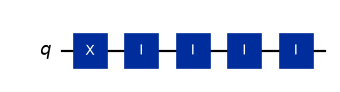

t2 with 4 idle steps


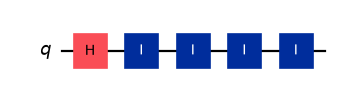

In [7]:
for name in ("t1", "t2"):
    print(name, "with 4 idle steps")
    display(enc.build_circuit(name, 4).draw("mpl", scale=0.8))
    plt.close()

## Step 3: Execution (attach the noise and simulate)

Aer lets us attach an error to any gate by name. Three lines do the work:

1. `kraus_error(kraus)` wraps our four matrices in an error object. Aer checks that they satisfy the completeness condition.
2. `NoiseModel()` is an empty collection of errors.
3. `add_all_qubit_quantum_error(error, ["id"])` says: after every `id` gate, on every qubit, apply this error.

That is the whole noise model. No other gate has noise in it, so the `X` and `H` that prepare the states are perfect.

In [8]:
model = execution.make_noise_model(STEP, T1, T2)
print(model)

NoiseModel:
  Basis gates: ['cx', 'id', 'rz', 'sx']
  Instructions with noise: ['id']
  All-qubits errors: ['id']


We then simulate with the density-matrix simulator and read $\rho$ directly instead of sampling shots. There is no shot noise, so any difference from the formula can only come from the model. Each circuit is also run **without** the noise model, for reference.

In [9]:
steps = np.arange(0, 301, 10)  # 0 to 300 idle steps = 0 to 300 us
data = {name: execution.run(name, steps, STEP, T1, T2) for name in ("t1", "t2")}

print("T1 circuit, 100 steps, final rho with noise:")
i = list(steps).index(100)
print(data["t1"]["rho"][i].real.round(4))
print("and without noise:")
print(data["t1"]["rho_ideal"][i].real.round(4))

T1 circuit, 100 steps, final rho with noise:
[[0.6321 0.    ]
 [0.     0.3679]]
and without noise:
[[0. 0.]
 [0. 1.]]


## Step 4: Analysis (does the noise model match the formulas?)

For each circuit we have three curves of the same expectation value:

- **ideal**: no noise. It stays flat.
- **Kraus noise model**: the simulation with our operators on `id`.
- **formula**: $1 - 2e^{-t/T_1}$ for the T1 circuit and $e^{-t/T_2}$ for the T2 circuit. These are the curves fitted in the benchmarking notebook, with the same $T_1$ and $T_2$.

If the Kraus operators are right, the points sit on the formula. The small panels show their difference.

T1 = 100 us, T2 = 70 us
circuit    t (us)     ideal     model   formula
t1            0.0   -1.0000   -1.0000   -1.0000
t1           70.0   -1.0000    0.0068    0.0068
t1          150.0   -1.0000    0.5537    0.5537
t1          220.0   -1.0000    0.7784    0.7784
t1          300.0   -1.0000    0.9004    0.9004
t1       largest |model - formula| = 4.1e-15
t2            0.0    1.0000    1.0000    1.0000
t2           70.0    1.0000    0.3679    0.3679
t2          150.0    1.0000    0.1173    0.1173
t2          220.0    1.0000    0.0432    0.0432
t2          300.0    1.0000    0.0138    0.0138
t2       largest |model - formula| = 2.1e-15


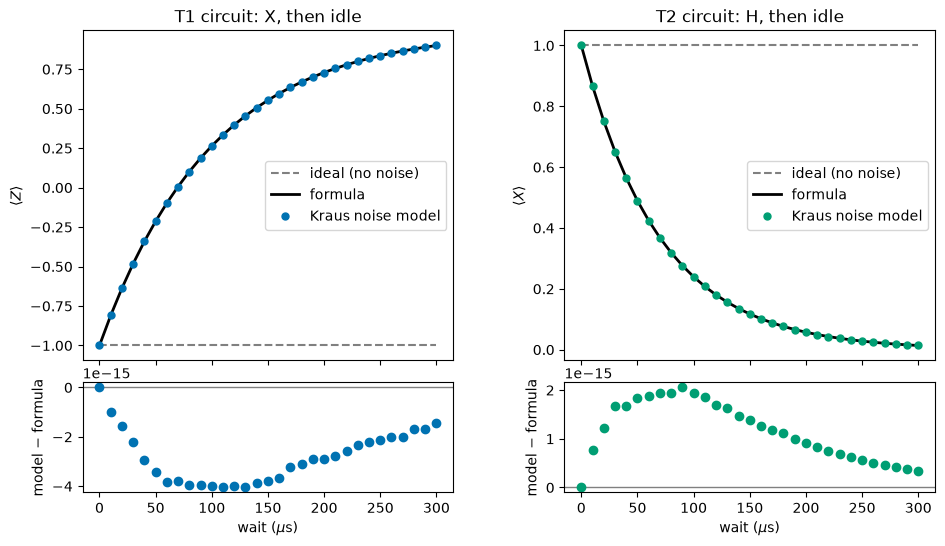

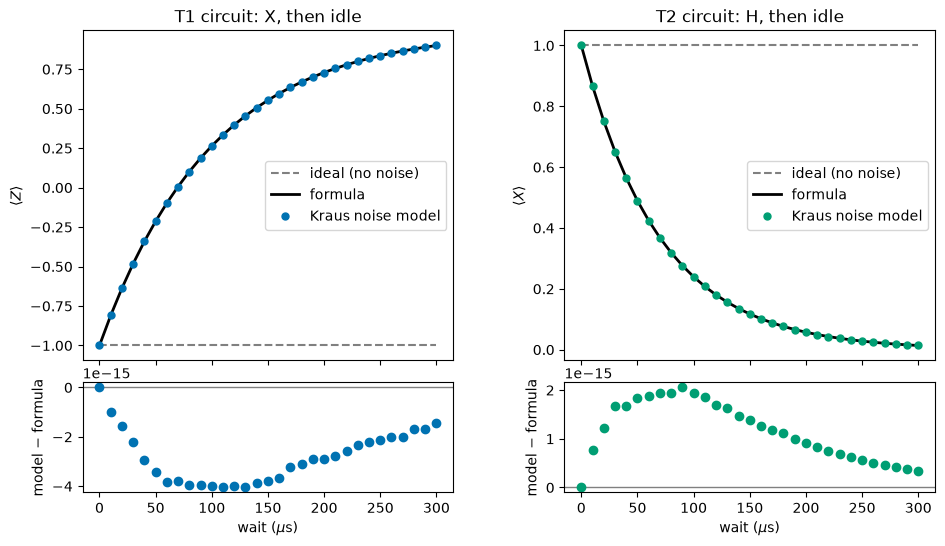

In [10]:
results = analysis.analyze(data, None, T1, T2)
fig = analysis.plot_compare(results)
display(fig)
plt.close(fig)

The noise model and the formula agree to about $10^{-15}$, which is rounding error. Nothing was fitted: we built the operators from $T_1$ and $T_2$ and the simulation reproduced both decay curves. Compare this with the benchmarking notebook, where we went the other way: from noisy data to $T_1$ and $T_2$. Together the two notebooks go both ways.

### What happened to the density matrix

The curves above are summaries. The density matrix holds the full story, and the two ways of losing information show up in different entries.

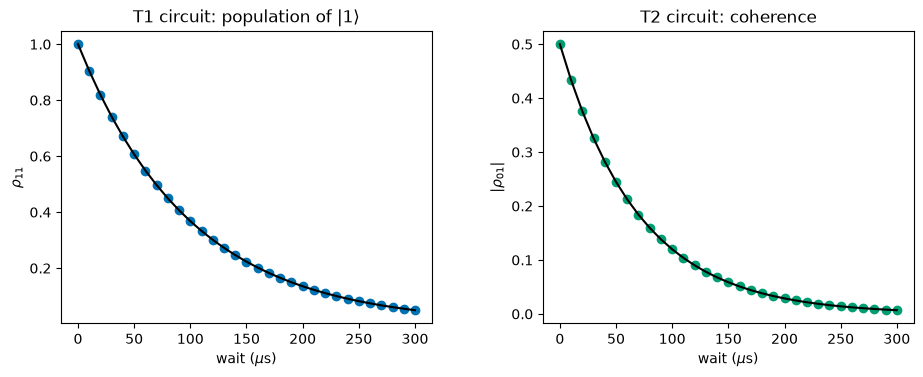

In [11]:
t_us = np.array(data["t1"]["times_us"])
p1 = [r[1, 1].real for r in data["t1"]["rho"]]  # T1 circuit: weight on |1>
c = [abs(r[0, 1]) for r in data["t2"]["rho"]]  # T2 circuit: size of the coherence

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"wspace": 0.3})
axes[0].plot(t_us, p1, "o", color=analysis.COLORS["t1"])
axes[0].plot(t_us, np.exp(-t_us / T1), "k-", lw=1.5)
axes[0].set_title("T1 circuit: population of $|1\\rangle$")
axes[0].set_ylabel(r"$\rho_{11}$")
axes[1].plot(t_us, c, "o", color=analysis.COLORS["t2"])
axes[1].plot(t_us, 0.5 * np.exp(-t_us / T2), "k-", lw=1.5)
axes[1].set_title("T2 circuit: coherence")
axes[1].set_ylabel(r"$|\rho_{01}|$")
for ax in axes:
    ax.set_xlabel(r"wait ($\mu$s)")
display(fig)
plt.close(fig)

The left panel is the population of $|1\rangle$ decaying with $T_1$. The right panel is the off-diagonal entry decaying with $T_2$. The black lines are $e^{-t/T_1}$ and $\tfrac12 e^{-t/T_2}$.

## Reading the results

- **The model reproduces both curves.** From two numbers and four small matrices, the simulator predicts what a waiting qubit does. You can use it on any circuit, not only on the two test circuits.
- **It is only as good as $T_1$ and $T_2$.** The operators contain nothing else. If the hardware values drift (and $T_1$ does, from hour to hour), the model drifts with them.
- **It has no memory.** Every step gets fresh, independent noise. This is the right model for fast noise. It is the wrong model for *slow* noise, which stays the same during one circuit and changes from run to run. The benchmarking notebook found $T_2^* \approx 41\,\mu$s for the Ramsey experiment but $T_2 \approx 70\,\mu$s for the echo, and this noise model has no way to tell the two apart: its qubit always dephases with $T_2$. Slow noise needs the ensemble of frequency offsets that the benchmarking simulator used.
- **It only covers waiting.** Gates take time and are imperfect, and read-out has its own error. A complete model has these as further errors attached to other gates.

## What to try next

1. Set `T2 = 2 * T1` (the largest allowed). What is $T_\varphi$? What does the phase-damping channel become?
2. Set `T2 = 200` with `T1 = 80`. What does `ops.dephasing_time` do, and why?
3. Replace `T1` and `T2` with the values you measured in the benchmarking notebook, or from the calibration page of `ibm_rensselaer`, and rerun.
4. Use `STEP = 10.0` instead of 1.0 and compare the two noise models at the same total wait. Why do they agree? (Hint: the step-splitting check in Step 1.)
5. Build a circuit that prepares $|+\rangle$, applies `X`, and idles. What do you expect for $\langle X\rangle$ and $\langle Z\rangle$? Run it with the noise model.
6. Change `T2` and see which curve moves. Change `T1` and see which curves move. Why does the T2 circuit depend on both?